# Анализ модели SASRec

Baseline без генеративной части: каузальный трансформер поверх истории, скоринг товаров
напрямую по эмбеддингам. Full-rank протокол — ранжирование по всему каталогу из 11 924
товаров, без sampled negatives.

Модель собирается из `configs/atg/sasrec.yaml` через реестр `builders.MODELS`, веса берутся
из чекпойнта. Секция 3 сверяет пересчитанный val с метриками в чекпойнте.

In [1]:
import os, random, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)                          # пути в yaml относительны корня проекта
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from builders import load_model_config
from data import build_dataloaders
from evaluate import evaluate
from train import seeded

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
print(f'Корень проекта: {ROOT}')

Корень проекта: d:\Skoltech\Thesis\DiffText4Rec


In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CONFIG_PATH = 'configs/atg/sasrec.yaml'
CKPT_DIR    = 'checkpoints/atg/sasrec'

TOP_K = (5, 10, 20)   # шире, чем eval.top_k в конфиге: @5 для наглядности
SEED  = 42            # EVAL_SEED тренера

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f'Device: {device}')

Device: cuda


## 1. Модель и чекпойнт

Гиперпараметры берутся из yaml, а не восстанавливаются из форм весов: `model_cfg` в чекпойнте
теперь хранит их целиком, поэтому расхождение конфига с обученной моделью видно сразу.

In [3]:
# ════════════════════════════════════════════════════════════
# Модель собирается по конфигу, веса — из чекпойнта
# ════════════════════════════════════════════════════════════
spec, cfg = load_model_config(CONFIG_PATH)
model = spec.build(cfg).to(device).eval()

ckpt_path = Path(CKPT_DIR) / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = Path(CKPT_DIR) / 'latest.pt'
ckpt = torch.load(ckpt_path, map_location='cpu', mmap=True)
model.load_state_dict(ckpt['model_state'])      # строго: архитектура из yaml должна совпасть

N_ITEMS   = model.n_items
LOSS_TYPE = model.loss     # infonce → скоринг косинусный, ce → скалярное произведение

print(f'{ckpt_path} | эпоха {ckpt["epoch"]}, шаг {ckpt["step"]}')
# У чекпойнтов, обученных до того, как SASRec получил config(), model_cfg пустой
print(f'model_cfg: {ckpt.get("model_cfg") or "не записан (чекпойнт старше SASRec.config())"}')
print(f'метрики в чекпойнте: {ckpt["metrics"]}')
print(f'{model.param_summary()}')

checkpoints\sasrec\best.pt | эпоха 90, шаг 5400
model_cfg: не записан (чекпойнт старше SASRec.config())
метрики в чекпойнте: {'HR@10': 0.047398246824741364, 'NDCG@10': 0.03100994974374771, 'HR@20': 0.061308603733778, 'NDCG@20': 0.034494467079639435}
{'total_trainable': 1627520, 'total_frozen': 0}


## 2. Данные

`batch_size` берём из конфига — тот же, что при обучении, чтобы метрики были сопоставимы
с логом.

In [4]:
loaders = build_dataloaders(data_dir=cfg.data.data_dir, batch_size=cfg.data.batch_size,
                            num_workers=0, seq_len=cfg.data.max_seq_len, splits=('val', 'test'))
for split, loader in loaders.items():
    print(f'{split:5s}: {len(loader.dataset):,} sequences')

val  : 1,941 sequences
test : 1,942 sequences


## 3. Метрики на val и test

HR@K — доля историй, где таргет попал в top-K; NDCG@K — 1/log2(rank+1) при попадании.
Сэмплинга у SASRec нет, поэтому результат детерминирован: разброса по сидам не будет,
а пересчитанный val обязан совпасть с метриками в чекпойнте.

In [5]:
results = {}
for split in ('val', 'test'):
    with seeded(SEED, device):
        results[split] = evaluate(model=model, dataloader=loaders[split], top_k_values=TOP_K,
                                  num_sample_steps=1,   # SASRec не сэмплирует, аргумент для совместимости
                                  w_cfg=0.0, device=device, show_progress=True)
    print(f'{split}: ' + '  '.join(f'{k}={v:.4f}' for k, v in results[split].items()))

saved = ckpt['metrics']
diff  = max(abs(results['val'][k] - v) for k, v in saved.items())
verdict = 'модель загружена корректно' if diff < 1e-3 else 'НЕ совпадает: проверь CONFIG_PATH и CKPT_DIR'
print(f'\nmax |val пересчёт − val чекпойнт| = {diff:.1e} → {verdict}')

metrics_df = pd.DataFrame(results).T.round(4)
metrics_df.index.name = 'split'
metrics_df

val: HR@5=0.0350  NDCG@5=0.0271  HR@10=0.0474  NDCG@10=0.0310  HR@20=0.0613  NDCG@20=0.0345


test: HR@5=0.0350  NDCG@5=0.0246  HR@10=0.0479  NDCG@10=0.0288  HR@20=0.0685  NDCG@20=0.0339

max |val пересчёт − val чекпойнт| = 0.0e+00 → модель загружена корректно


,HR@5,NDCG@5,HR@10,NDCG@10,HR@20,NDCG@20
split,,,,,,
val,0.035,0.0271,0.0474,0.0310,0.0613,0.0345
test,0.035,0.0246,0.0479,0.0288,0.0685,0.0339


## 4. Сравнение со случайным ранжированием

Аналитический бейзлайн: HR@K = K / N_items, NDCG@K = (Σ_{r<K} 1/log2(r+2)) / N_items.
Lift показывает, во сколько раз модель лучше случая.

In [6]:
def analytical_random(k):
    return k / N_ITEMS, sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS


rows = []
for split in ('val', 'test'):
    for k in TOP_K:
        hr_rnd, nd_rnd = analytical_random(k)
        hr, nd = results[split][f'HR@{k}'], results[split][f'NDCG@{k}']
        rows.append({'split': split, 'K': k,
                     'HR': round(hr, 4), 'HR random': round(hr_rnd, 5), 'HR lift': round(hr / hr_rnd, 1),
                     'NDCG': round(nd, 4), 'NDCG random': round(nd_rnd, 5), 'NDCG lift': round(nd / nd_rnd, 1)})

comparison = pd.DataFrame(rows).set_index(['split', 'K'])
comparison

HR  HR random  HR lift    NDCG  NDCG random  NDCG lift
split K                                                             
val   5   0.0350    0.00042     83.5  0.0271      0.00025      109.6
      10  0.0474    0.00084     56.5  0.0310      0.00038       81.4
      20  0.0613    0.00168     36.6  0.0345      0.00059       58.4
test  5   0.0350    0.00042     83.5  0.0246      0.00025       99.6
      10  0.0479    0.00084     57.1  0.0288      0.00038       75.5
      20  0.0685    0.00168     40.8  0.0339      0.00059       57.4

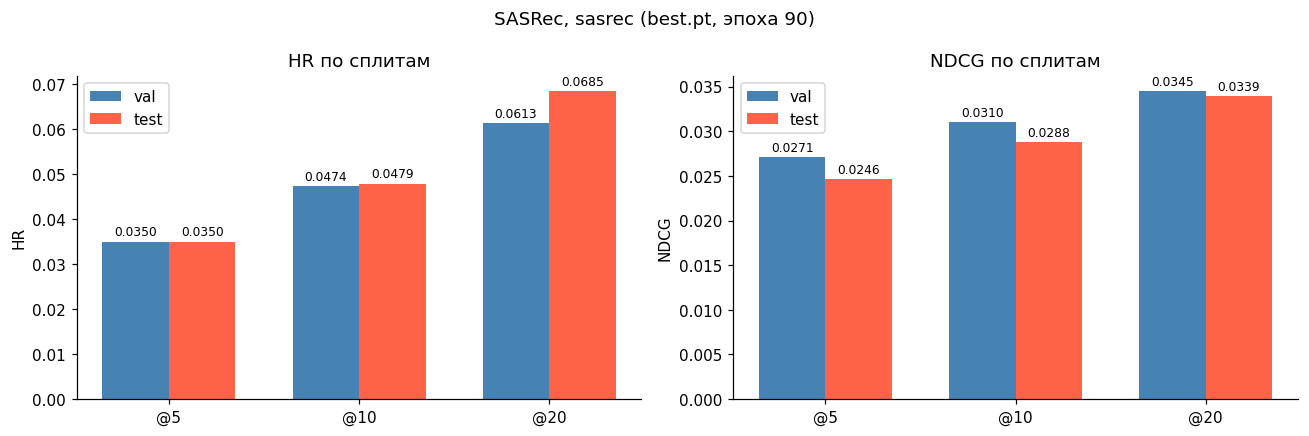

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x, width = np.arange(len(TOP_K)), 0.35

for ax, metric in zip(axes, ['HR', 'NDCG']):
    for i, (split, color) in enumerate([('val', 'steelblue'), ('test', 'tomato')]):
        vals = [results[split][f'{metric}@{k}'] for k in TOP_K]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, label=split, color=color)
        ax.bar_label(bars, fmt='%.4f', fontsize=8, padding=2)
    ax.set_xticks(x, [f'@{k}' for k in TOP_K])
    ax.set_ylabel(metric); ax.set_title(f'{metric} по сплитам'); ax.legend()

fig.suptitle(f'SASRec, {Path(CKPT_DIR).name} ({ckpt_path.name}, эпоха {ckpt["epoch"]})')
fig.tight_layout(); plt.show()

## 5. Кривые обучения

`log_train.csv` — лосс по эпохам, `log_val.csv` — val-лосс и метрики каждые `eval.every_epochs`
эпох; строка с `epoch == 'test'` — это финальная оценка на best.pt, а не эпоха, её отбрасываем.
В логах старых прогонов есть колонка `train_ndcg20` — если она там есть, рисуем и её.

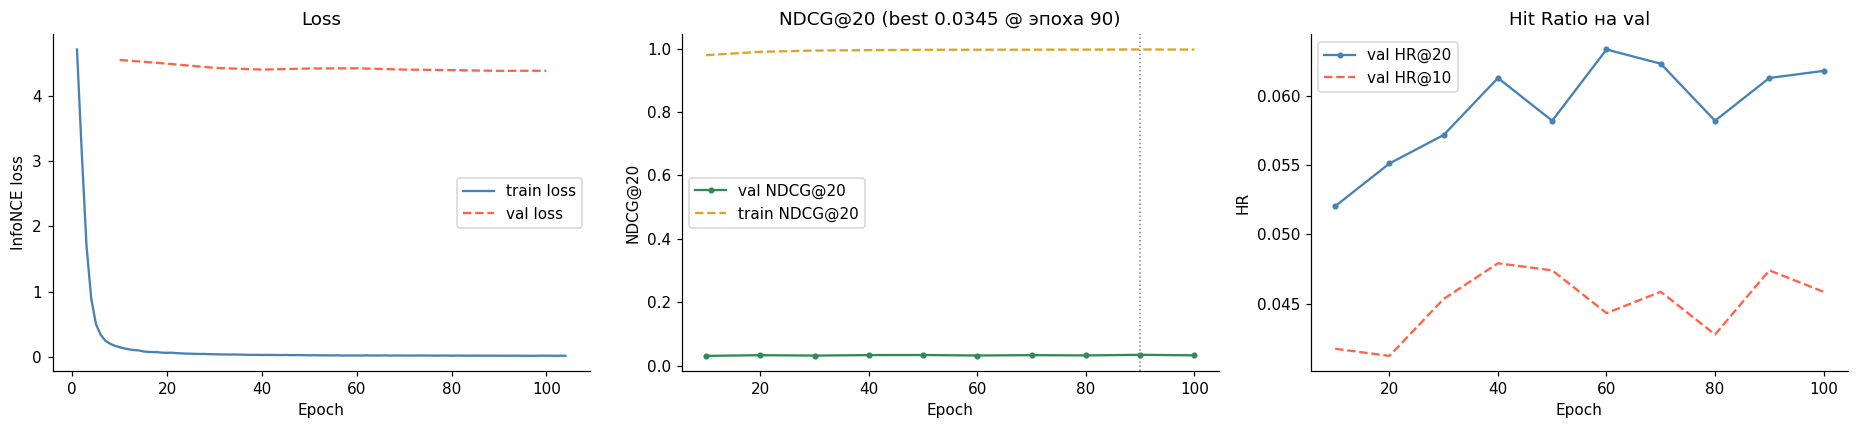

In [8]:
log_dir   = Path(CKPT_DIR)
train_log = pd.read_csv(log_dir / 'log_train.csv', comment='#')
val_raw   = pd.read_csv(log_dir / 'log_val.csv', comment='#')
val_log   = val_raw[val_raw['epoch'].astype(str) != 'test'].apply(pd.to_numeric, errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

ax = axes[0]
ax.plot(train_log['epoch'], train_log['loss'], color='steelblue', lw=1.5, label='train loss')
ax.plot(val_log['epoch'], val_log['val_loss'], color='tomato', lw=1.5, ls='--', label='val loss')
ax.set_xlabel('Epoch'); ax.set_ylabel('InfoNCE loss' if LOSS_TYPE == 'infonce' else 'CE loss')
ax.set_title('Loss'); ax.legend()

ax = axes[1]
ax.plot(val_log['epoch'], val_log['NDCG@20'], color='seagreen', lw=1.5, marker='o', ms=3,
        label='val NDCG@20')
if 'train_ndcg20' in val_log:
    ax.plot(val_log['epoch'], val_log['train_ndcg20'], color='goldenrod', lw=1.5, ls='--',
            label='train NDCG@20')
best = val_log.loc[val_log['NDCG@20'].idxmax()]
ax.axvline(best['epoch'], color='grey', ls=':', lw=1)
ax.set_xlabel('Epoch'); ax.set_ylabel('NDCG@20')
ax.set_title(f'NDCG@20 (best {best["NDCG@20"]:.4f} @ эпоха {int(best["epoch"])})'); ax.legend()

ax = axes[2]
ax.plot(val_log['epoch'], val_log['HR@20'], color='steelblue', lw=1.5, marker='o', ms=3,
        label='val HR@20')
ax.plot(val_log['epoch'], val_log['HR@10'], color='tomato', lw=1.5, ls='--', label='val HR@10')
ax.set_xlabel('Epoch'); ax.set_ylabel('HR'); ax.set_title('Hit Ratio на val'); ax.legend()

fig.tight_layout(); plt.show()